In [1]:
print(f'NOrm Flow task FashionMNIST')

NOrm Flow task FashionMNIST


In [2]:
# PyTorch for deep learning
import torch
from torch import nn, optim, distributions
from torch.nn import functional as F

# For data visualization
import matplotlib.pyplot as plt
from pylab import rcParams

# For generating our dataset
import numpy as np
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
transform = transforms.ToTensor()

# Fashion-MNIST
train_full = datasets.FashionMNIST(root="./data_fashion", train=True,  download=True, transform=transform)
test_set   = datasets.FashionMNIST(root="./data_fashion", train=False, download=True, transform=transform)
CLASSES = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot']

# For file operations
import os

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


100.0%
100.0%
100.0%
100.0%

All libraries imported successfully!
PyTorch version: 2.11.0+cu128
Using device: CUDA


In [3]:
# Training configuration
BATCH_SIZE = 256
EPOCHS = 30
LOG_INTERVAL = 50
LR = 1e-3

# Data
IN_CHANNELS = 1
IMG_SIZE = 28

# Model architecture
N_SCALES = 2            # How many times we do squeeze + split (28 -> 14 -> 7)
N_FLOW_STEPS = 4        # Coupling layers per scale
HIDDEN_CHANNELS = 64    # Channels in the hidden layers of the coupling CNN
N_RES_BLOCKS = 2        # Depth of the coupling CNN (residual blocks)
KERNEL_SIZE = 3         # Kernel size of convolutions
PADDING = 1             # Keeps spatial size unchanged for kernel 3

# Visualization settings
SAVE_PLT_INTERVAL = 1   # How often to save plots
N_SAMPLES = 64          # How many images to generate for visualization
TEMPERATURE = 0.7       # Scale of z when sampling (lower = cleaner, less diverse)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("🔧 Configuration set up!")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Epochs: {EPOCHS}")
print(f"   Scales: {N_SCALES}, flow steps per scale: {N_FLOW_STEPS}")
print(f"   Hidden channels: {HIDDEN_CHANNELS}")
print(f"   Device: {device}")

🔧 Configuration set up!
   Batch size: 256
   Epochs: 30
   Scales: 2, flow steps per scale: 4
   Hidden channels: 64
   Device: cuda


In [4]:
train_set, val_set = random_split(
    train_full, [55000, 5000],
    generator=torch.Generator().manual_seed(42)
)

kwargs = {'num_workers': 1, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, **kwargs)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)

x, y = next(iter(train_loader))
print(len(train_loader), len(val_loader), len(test_loader))
print(x.shape, x.min().item(), x.max().item())

215 20 40
torch.Size([256, 1, 28, 28]) 0.0 1.0


Train: 55000, Val: 5000, Test: 10000
Batch shape: torch.Size([256, 1, 28, 28])


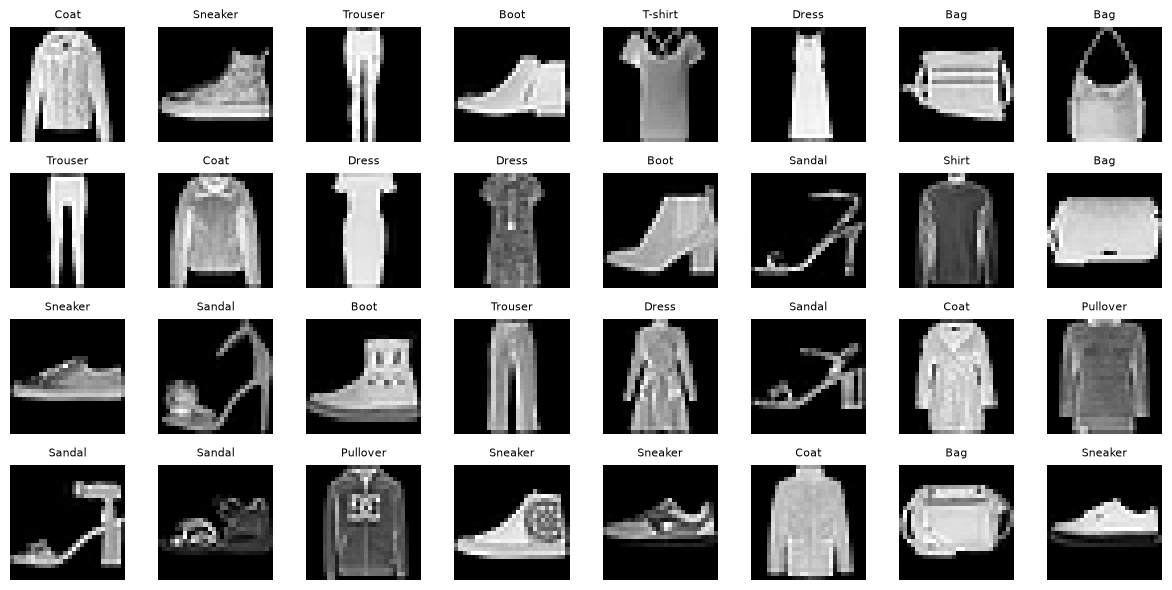

In [5]:
print(f"Train: {len(train_set)}, Val: {len(val_set)}, Test: {len(test_set)}")

x, y = next(iter(train_loader))
print(f"Batch shape: {x.shape}")

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x[i, 0], cmap='gray')
    ax.set_title(CLASSES[int(y[i])], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [6]:
class ResBlock(nn.Module):
    def __init__(self, channels, kernel_size, padding):
        super().__init__()
        self.net = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),

            nn.ReLU(),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
        )
    def forward(self, x):
        return x + self.net(x)

class CouplingLayer(nn.Module):
    def __init__(self, in_channels, hidden_channels, n_res_blocks, mask, kernel_size=3, padding=1):
        super().__init__()
        self.register_buffer('mask', mask)
        self.inp = nn.Conv2d(in_channels, hidden_channels, kernel_size, padding=padding)
        self.blocks = nn.Sequential(*[ResBlock(hidden_channels, kernel_size, padding) for _ in range(n_res_blocks)])
        self.out = nn.Conv2d(hidden_channels, 2 * in_channels, kernel_size, padding=padding)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)
        self.scale = nn.Parameter(torch.ones(1, in_channels, 1, 1))
        
    def st(self, x_masked):
        h = self.out(F.relu(self.blocks(self.inp(x_masked))))
        s, t = h.chunk(2, dim=1)
        return self.scale * torch.tanh(s) * (1 - self.mask), t * (1 - self.mask)
    def forward(self, x):
        s, t = self.st(x * self.mask)
        return x * torch.exp(s) + t, s.sum(dim=(1, 2, 3))
    def inverse(self, y):
        s, t = self.st(y * self.mask)
        return (y - t) * torch.exp(-s)

def checkerboard_mask(h, w, flip=False):
    m = ((torch.arange(h).view(-1, 1) + torch.arange(w).view(1, -1)) % 2).float().view(1, 1, h, w)
    return 1 - m if flip else m

def channel_mask(c, flip=False):
    m = torch.zeros(1, c, 1, 1)
    m[:, : c // 2] = 1
    return 1 - m if flip else m

In [7]:
class FlowStep(nn.Module):
    def __init__(self, in_channels, hidden_channels, n_res_blocks, n_layers, size, mask_type='checkerboard'):
        super().__init__()
        assert n_layers % 2 == 0
        layers = []
        for i in range(n_layers):
            flip = i % 2 == 1
            if (i // 2) % 2 == 0:
                mask = checkerboard_mask(size, size, flip)
            else:
                mask = channel_mask(in_channels, flip)
            layers.append(CouplingLayer(in_channels, hidden_channels, n_res_blocks, mask))
        self.layers = nn.ModuleList(layers)
    def forward(self, x):
        ldj_sum = 0
        for layer in self.layers:
            x, ldj = layer(x)
            ldj_sum = ldj_sum + ldj
        return x, ldj_sum
    def inverse(self, z):
        for layer in reversed(self.layers):
            z = layer.inverse(z)
        return z

In [8]:
# here I also tried to understand how we transform vectors and how shapes change

import math

# Mini example for squeeze, a 4x4 image (B=1, C=1):
#
#  0  1 |  2  3          after squeeze (1, 4, 2, 2):
#  4  5 |  6  7          channel 0: [[ 0,  2], [ 8, 10]]   top-left pixel of every block
# ------+------          channel 1: [[ 1,  3], [ 9, 11]]   top-right
#  8  9 | 10 11          channel 2: [[ 4,  6], [12, 14]]   bottom-left
# 12 13 | 14 15          channel 3: [[ 5,  7], [13, 15]]   bottom-right
#
# Every 2x2 block became one "pixel" with 4 channels: 16 numbers before, 16 after.

def squeeze(x):
    b, c, h, w = x.shape                                # (B, 1, 28, 28)
    x = x.view(b, c, h // 2, 2, w // 2, 2)              # (B, 1, 14, 2, 14, 2)  axes: [b, c, block_row, row_in_block, block_col, col_in_block]
    x = x.permute(0, 1, 3, 5, 2, 4).contiguous()        # (B, 1, 2, 2, 14, 14)  axes: [b, c, row_in_block, col_in_block, block_row, block_col]
    return x.view(b, c * 4, h // 2, w // 2)             # (B, 4, 14, 14)        the two size-2 axes merged into channels: channel = row_in_block * 2 + col_in_block

def unsqueeze(x):
    b, c, h, w = x.shape                                # (B, 4, 14, 14)
    x = x.view(b, c // 4, 2, 2, h, w)                   # (B, 1, 2, 2, 14, 14)  channels split back into (row_in_block, col_in_block)
    x = x.permute(0, 1, 4, 2, 5, 3).contiguous()        # (B, 1, 14, 2, 14, 2)  axes: [b, c, block_row, row_in_block, block_col, col_in_block]
    return x.view(b, c // 4, h * 2, w * 2)              # (B, 1, 28, 28)        row = block_row * 2 + row_in_block, same for columns


def gaussian_log_prob(z):
    return distributions.Normal(0, 1).log_prob(z).sum(dim=(1, 2, 3))

In [9]:
class RealNVP(nn.Module):
    def __init__(self, in_channels, img_size, hidden_channels, n_res_blocks, n_scales, n_flow_steps, mask_type='checkerboard'):
        super().__init__()
        assert img_size % (2 ** n_scales) == 0
        self.steps = nn.ModuleList()
        self.z_shapes = []
        c, s = in_channels, img_size
        for i in range(n_scales):
            c, s = c * 4, s // 2
            self.steps.append(FlowStep(c, hidden_channels, n_res_blocks, n_flow_steps, s, mask_type))
            if i < n_scales - 1:
                c = c // 2
            self.z_shapes.append((c, s, s))
    def forward(self, x):
        zs = []
        ldj_sum = 0
        for i, step in enumerate(self.steps):
            x, ldj = step(squeeze(x))
            ldj_sum = ldj_sum + ldj
            if i < len(self.steps) - 1:
                z, x = x.chunk(2, dim=1)
                zs.append(z)
        zs.append(x)
        return zs, ldj_sum
    def log_prob(self, x):
        zs, ldj = self(x)
        return sum(gaussian_log_prob(z) for z in zs) + ldj
    def inverse(self, zs):
        x = zs[-1]
        for i in reversed(range(len(self.steps))):
            if i < len(self.steps) - 1:
                x = torch.cat([zs[i], x], dim=1)
            x = unsqueeze(self.steps[i].inverse(x))
        return x
    @torch.no_grad()
    def sample(self, n, temperature=1.0):
        device = next(self.parameters()).device
        zs = [temperature * torch.randn(n, *shape, device=device) for shape in self.z_shapes]
        return self.inverse(zs)

In [10]:
def preprocess(x):
    x = torch.round(x * 255)
    return (x + torch.rand_like(x)) / 256 - 0.5

def postprocess(x):
    return (x + 0.5).clamp(0, 1)

In [11]:
model = RealNVP(IN_CHANNELS, IMG_SIZE, HIDDEN_CHANNELS, N_RES_BLOCKS, N_SCALES, N_FLOW_STEPS).to(device)
optimizer = optim.Adam(model.parameters(), lr=LR)
print(sum(p.numel() for p in model.parameters()))

x, _ = next(iter(train_loader))
x = preprocess(x.to(device))
with torch.no_grad():
    print(x.min().item(), x.max().item())
    print(-model.log_prob(x).mean().item())

1265296
-0.5 0.4999978542327881
787.059814453125


In [12]:
def train(epoch):
    model.train()
    total = 0
    for i, (x, _) in enumerate(train_loader):
        x = preprocess(x.to(device))
        loss = -model.log_prob(x).mean()
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 100.0)
        optimizer.step()
        total += loss.item() * x.size(0)
        if i % LOG_INTERVAL == 0:
            print(f'epoch {epoch} [{i}/{len(train_loader)}] loss {loss.item():.2f}')
    return total / len(train_loader.dataset)

In [13]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    total = 0
    for x, _ in loader:
        x = preprocess(x.to(device))
        total += -model.log_prob(x).sum().item()
    return total / len(loader.dataset)

In [14]:
import torchvision.utils as vutils

def sample(epoch, n=64, temperature=TEMPERATURE):
    model.eval()
    imgs = postprocess(model.sample(n, temperature)).cpu()
    grid = vutils.make_grid(imgs, nrow=8)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(f'epoch {epoch}, temperature {temperature}')
    plt.axis('off')
    if epoch % SAVE_PLT_INTERVAL == 0:
        os.makedirs('results_fashion', exist_ok=True)
        plt.savefig(f'results_fashion/samples_{epoch}.png')
    plt.show()

Starting training...

Epoch 1/30
------------------------------
epoch 1 [0/215] loss 785.62
epoch 1 [50/215] loss -674.08
epoch 1 [100/215] loss -850.08
epoch 1 [150/215] loss -984.82
epoch 1 [200/215] loss -1035.07


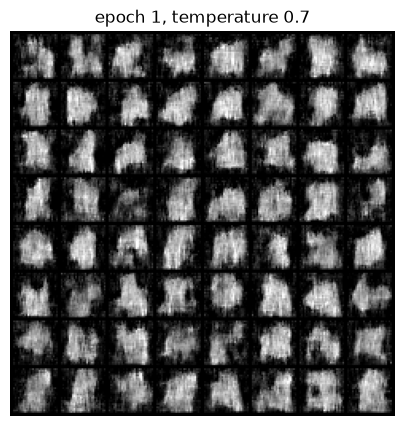

Epoch 1 summary:
   Train loss: -735.72
   Val loss:   -1045.52
   Saved best model

Epoch 2/30
------------------------------
epoch 2 [0/215] loss -1050.76
epoch 2 [50/215] loss -1136.33
epoch 2 [100/215] loss -1142.05
epoch 2 [150/215] loss -1161.11
epoch 2 [200/215] loss -1232.21


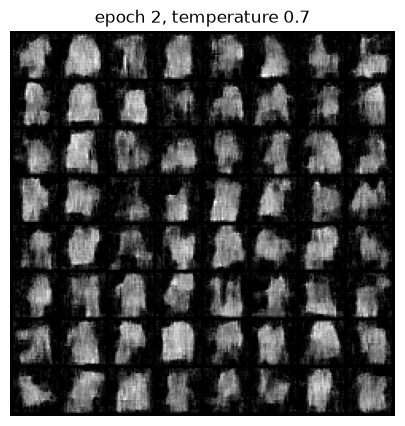

Epoch 2 summary:
   Train loss: -1133.51
   Val loss:   -1218.93
   Saved best model

Epoch 3/30
------------------------------
epoch 3 [0/215] loss -1229.39
epoch 3 [50/215] loss -1265.86
epoch 3 [100/215] loss -1281.44
epoch 3 [150/215] loss -1308.00
epoch 3 [200/215] loss -1343.33


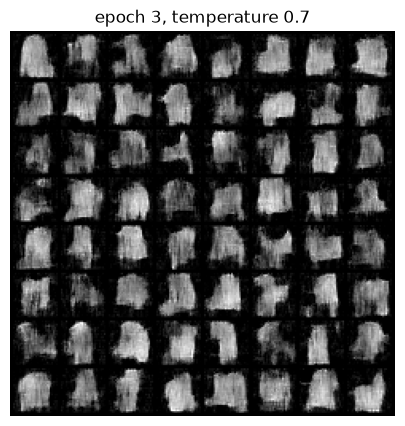

Epoch 3 summary:
   Train loss: -1301.62
   Val loss:   -1385.59
   Saved best model

Epoch 4/30
------------------------------
epoch 4 [0/215] loss -1404.79
epoch 4 [50/215] loss -1378.98
epoch 4 [100/215] loss -1395.75
epoch 4 [150/215] loss -1450.27
epoch 4 [200/215] loss -1498.38


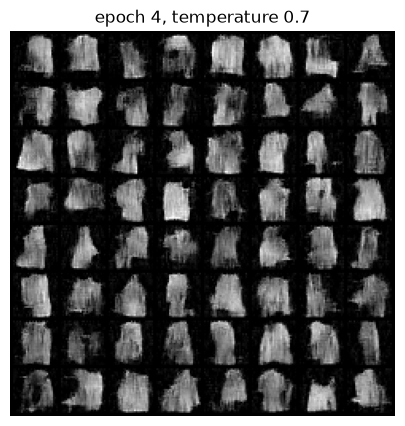

Epoch 4 summary:
   Train loss: -1436.21
   Val loss:   -1471.73
   Saved best model

Epoch 5/30
------------------------------
epoch 5 [0/215] loss -1489.63
epoch 5 [50/215] loss -1528.11
epoch 5 [100/215] loss -1481.22
epoch 5 [150/215] loss -1574.93
epoch 5 [200/215] loss -1540.03


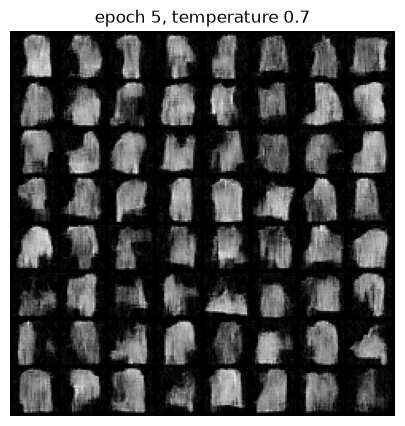

Epoch 5 summary:
   Train loss: -1522.31
   Val loss:   -1564.91
   Saved best model

Epoch 6/30
------------------------------
epoch 6 [0/215] loss -1548.69
epoch 6 [50/215] loss -1517.81
epoch 6 [100/215] loss -1619.46
epoch 6 [150/215] loss -1602.85
epoch 6 [200/215] loss -1617.78


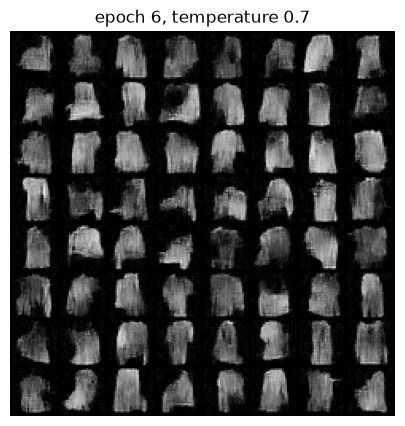

Epoch 6 summary:
   Train loss: -1593.03
   Val loss:   -1648.91
   Saved best model

Epoch 7/30
------------------------------
epoch 7 [0/215] loss -1638.39
epoch 7 [50/215] loss -1658.18
epoch 7 [100/215] loss -1643.95
epoch 7 [150/215] loss -1663.77
epoch 7 [200/215] loss -1718.17


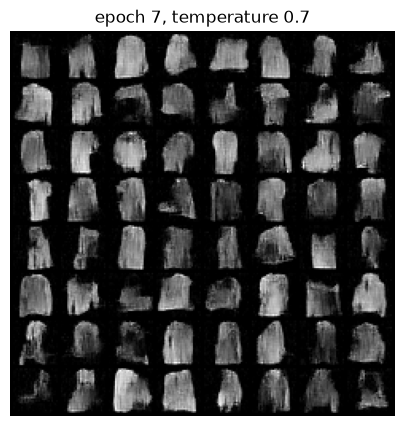

Epoch 7 summary:
   Train loss: -1670.70
   Val loss:   -1693.88
   Saved best model

Epoch 8/30
------------------------------
epoch 8 [0/215] loss -1710.80
epoch 8 [50/215] loss -1732.24
epoch 8 [100/215] loss -1777.06
epoch 8 [150/215] loss -1713.09
epoch 8 [200/215] loss -1762.11


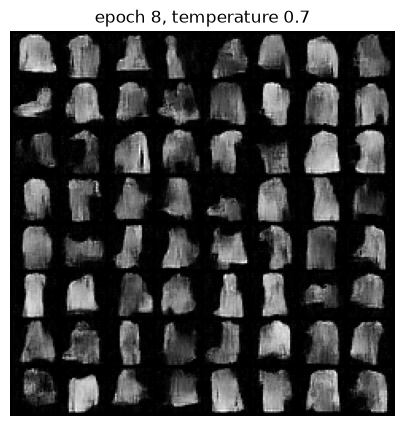

Epoch 8 summary:
   Train loss: -1730.98
   Val loss:   -1767.73
   Saved best model

Epoch 9/30
------------------------------
epoch 9 [0/215] loss -1754.24
epoch 9 [50/215] loss -1701.38
epoch 9 [100/215] loss -1858.54
epoch 9 [150/215] loss -1757.39
epoch 9 [200/215] loss -1755.64


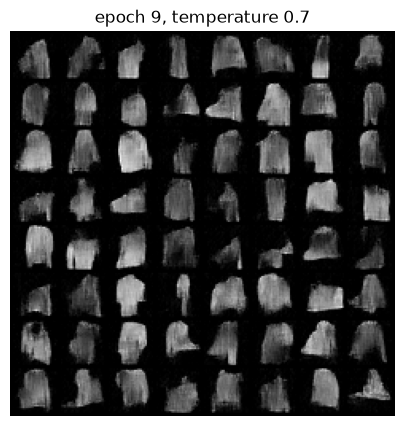

Epoch 9 summary:
   Train loss: -1790.30
   Val loss:   -1766.83

Epoch 10/30
------------------------------
epoch 10 [0/215] loss -1770.06
epoch 10 [50/215] loss -1807.75
epoch 10 [100/215] loss -1819.20
epoch 10 [150/215] loss -1893.48
epoch 10 [200/215] loss -1820.77


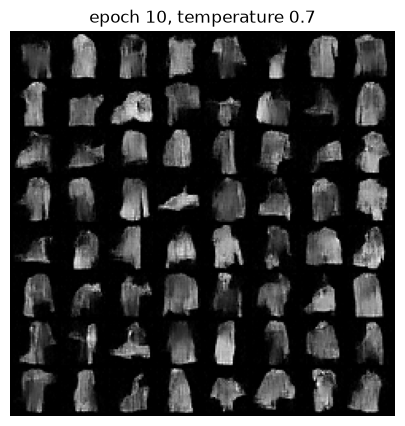

Epoch 10 summary:
   Train loss: -1832.53
   Val loss:   -1825.69
   Saved best model

Epoch 11/30
------------------------------
epoch 11 [0/215] loss -1807.89
epoch 11 [50/215] loss -1847.40
epoch 11 [100/215] loss -1820.86
epoch 11 [150/215] loss -1870.11
epoch 11 [200/215] loss -1948.34


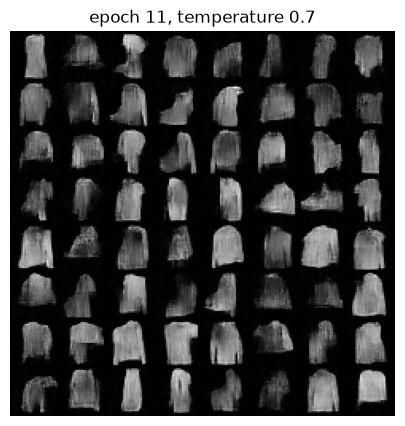

Epoch 11 summary:
   Train loss: -1865.56
   Val loss:   -1882.94
   Saved best model

Epoch 12/30
------------------------------
epoch 12 [0/215] loss -1903.57
epoch 12 [50/215] loss -1887.31
epoch 12 [100/215] loss -1941.04
epoch 12 [150/215] loss -1924.06
epoch 12 [200/215] loss -1877.65


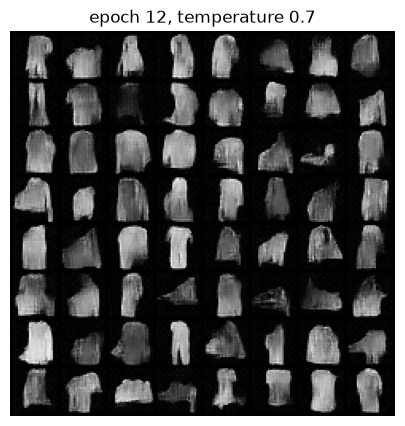

Epoch 12 summary:
   Train loss: -1922.87
   Val loss:   -1887.59
   Saved best model

Epoch 13/30
------------------------------
epoch 13 [0/215] loss -1869.31
epoch 13 [50/215] loss -1901.87
epoch 13 [100/215] loss -1973.83
epoch 13 [150/215] loss -1972.62
epoch 13 [200/215] loss -1933.61


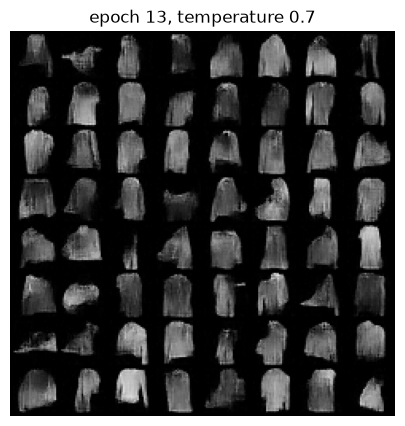

Epoch 13 summary:
   Train loss: -1949.50
   Val loss:   -1980.58
   Saved best model

Epoch 14/30
------------------------------
epoch 14 [0/215] loss -2018.34
epoch 14 [50/215] loss -1971.44
epoch 14 [100/215] loss -2005.63
epoch 14 [150/215] loss -1936.82
epoch 14 [200/215] loss -1974.90


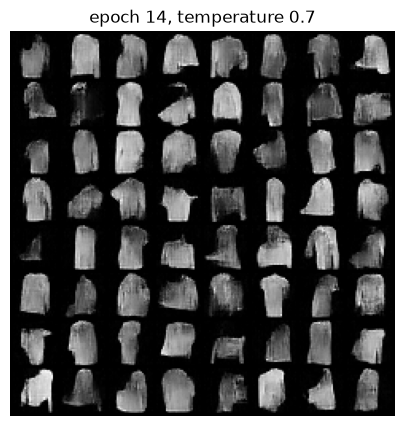

Epoch 14 summary:
   Train loss: -1970.75
   Val loss:   -2025.10
   Saved best model

Epoch 15/30
------------------------------
epoch 15 [0/215] loss -2011.39
epoch 15 [50/215] loss -2049.62
epoch 15 [100/215] loss -1982.41
epoch 15 [150/215] loss -2030.71
epoch 15 [200/215] loss -1974.17


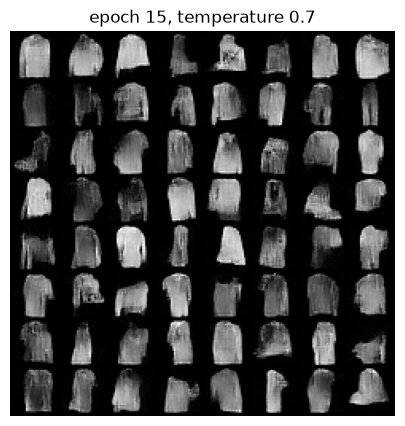

Epoch 15 summary:
   Train loss: -2005.98
   Val loss:   -2042.59
   Saved best model

Epoch 16/30
------------------------------
epoch 16 [0/215] loss -2089.94
epoch 16 [50/215] loss -2034.98
epoch 16 [100/215] loss -2023.66
epoch 16 [150/215] loss -2096.24
epoch 16 [200/215] loss -2090.13


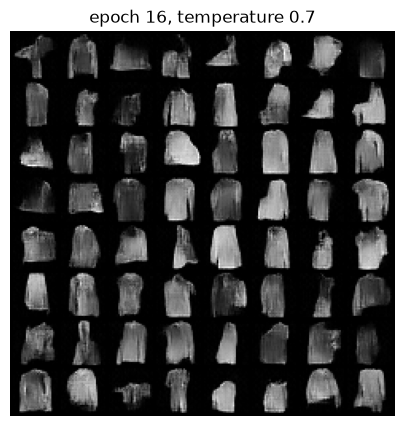

Epoch 16 summary:
   Train loss: -2050.82
   Val loss:   -2038.54

Epoch 17/30
------------------------------
epoch 17 [0/215] loss -2030.47
epoch 17 [50/215] loss -2098.09
epoch 17 [100/215] loss -2031.57
epoch 17 [150/215] loss -2071.56
epoch 17 [200/215] loss -2076.06


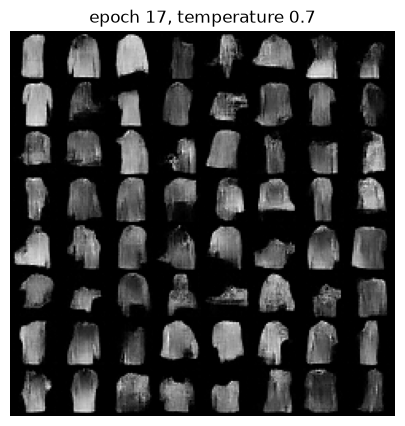

Epoch 17 summary:
   Train loss: -2067.95
   Val loss:   -2062.90
   Saved best model

Epoch 18/30
------------------------------
epoch 18 [0/215] loss -2083.98
epoch 18 [50/215] loss -2075.31
epoch 18 [100/215] loss -2105.35
epoch 18 [150/215] loss -2155.79
epoch 18 [200/215] loss -2132.42


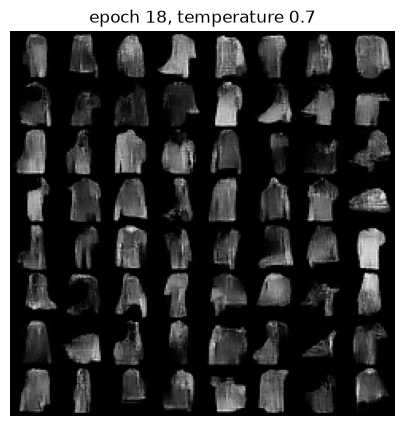

Epoch 18 summary:
   Train loss: -2097.60
   Val loss:   -2103.76
   Saved best model

Epoch 19/30
------------------------------
epoch 19 [0/215] loss -2134.25
epoch 19 [50/215] loss -2124.53
epoch 19 [100/215] loss -2126.95
epoch 19 [150/215] loss -2137.54
epoch 19 [200/215] loss -2137.23


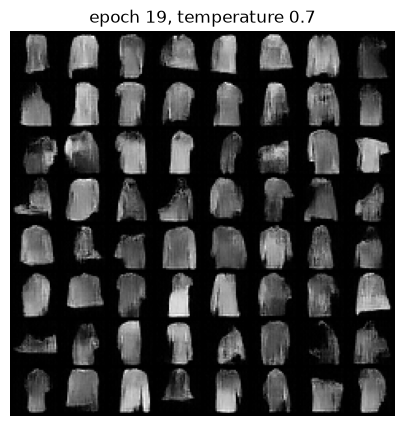

Epoch 19 summary:
   Train loss: -2118.37
   Val loss:   -2114.48
   Saved best model

Epoch 20/30
------------------------------
epoch 20 [0/215] loss -2112.18
epoch 20 [50/215] loss -2152.82
epoch 20 [100/215] loss -2105.69
epoch 20 [150/215] loss -2194.34
epoch 20 [200/215] loss -2038.19


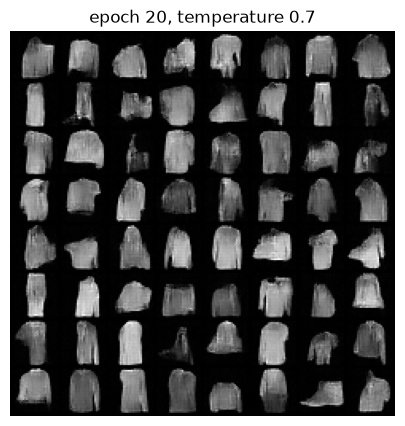

Epoch 20 summary:
   Train loss: -2144.35
   Val loss:   -2123.85
   Saved best model

Epoch 21/30
------------------------------
epoch 21 [0/215] loss -2119.99
epoch 21 [50/215] loss -2179.44
epoch 21 [100/215] loss -2174.92
epoch 21 [150/215] loss -2093.96
epoch 21 [200/215] loss -2170.97


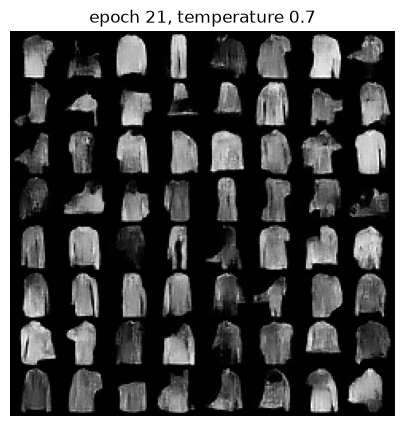

Epoch 21 summary:
   Train loss: -2150.73
   Val loss:   -2103.74

Epoch 22/30
------------------------------
epoch 22 [0/215] loss -2088.22
epoch 22 [50/215] loss -2087.67
epoch 22 [100/215] loss -2147.49
epoch 22 [150/215] loss -2154.00
epoch 22 [200/215] loss -2175.23


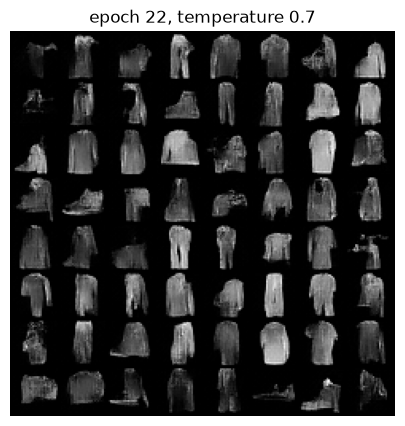

Epoch 22 summary:
   Train loss: -2183.18
   Val loss:   -2107.12

Epoch 23/30
------------------------------
epoch 23 [0/215] loss -2115.10
epoch 23 [50/215] loss -2030.97
epoch 23 [100/215] loss -2099.89
epoch 23 [150/215] loss -2170.46
epoch 23 [200/215] loss -2221.19


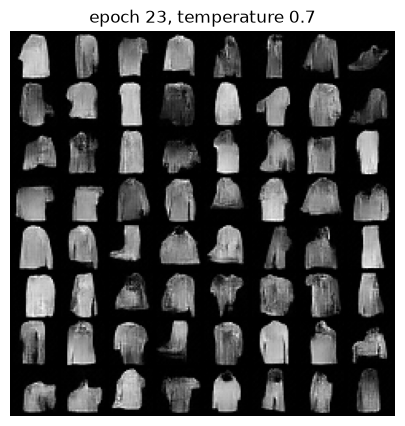

Epoch 23 summary:
   Train loss: -2156.91
   Val loss:   -2214.69
   Saved best model

Epoch 24/30
------------------------------
epoch 24 [0/215] loss -2220.94
epoch 24 [50/215] loss -2252.20
epoch 24 [100/215] loss -2209.33
epoch 24 [150/215] loss -2210.46
epoch 24 [200/215] loss -2235.64


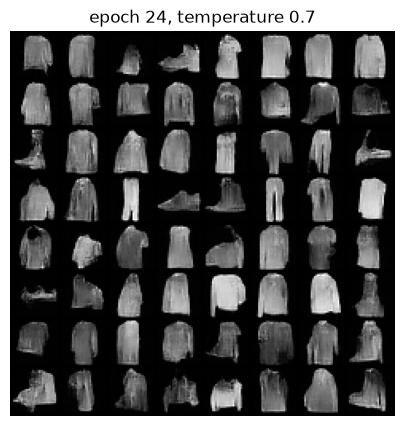

Epoch 24 summary:
   Train loss: -2218.70
   Val loss:   -2127.23

Epoch 25/30
------------------------------
epoch 25 [0/215] loss -2161.78
epoch 25 [50/215] loss -2285.13
epoch 25 [100/215] loss -2185.17
epoch 25 [150/215] loss -2237.76
epoch 25 [200/215] loss -2240.81


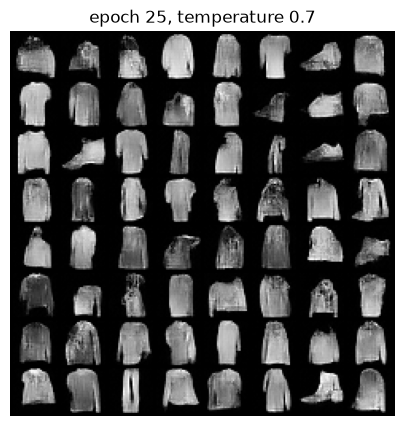

Epoch 25 summary:
   Train loss: -2223.68
   Val loss:   -2249.52
   Saved best model

Epoch 26/30
------------------------------
epoch 26 [0/215] loss -2308.65
epoch 26 [50/215] loss -2230.19
epoch 26 [100/215] loss -2190.31
epoch 26 [150/215] loss -2227.49
epoch 26 [200/215] loss -2248.98


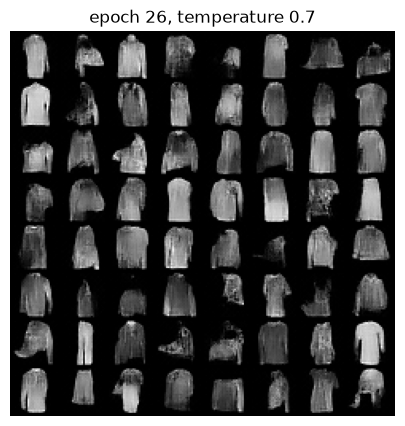

Epoch 26 summary:
   Train loss: -2244.11
   Val loss:   -2202.35

Epoch 27/30
------------------------------
epoch 27 [0/215] loss -2233.95
epoch 27 [50/215] loss -2215.40
epoch 27 [100/215] loss -2160.84
epoch 27 [150/215] loss -2271.25
epoch 27 [200/215] loss -2186.72


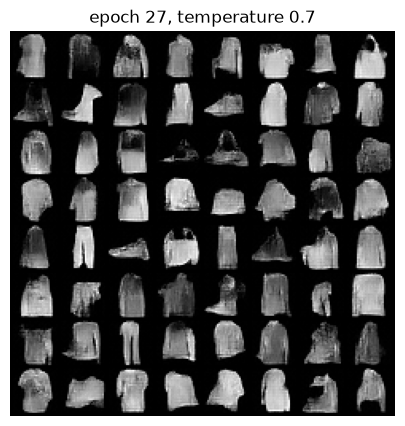

Epoch 27 summary:
   Train loss: -2238.23
   Val loss:   -2179.40

Epoch 28/30
------------------------------
epoch 28 [0/215] loss -2193.71
epoch 28 [50/215] loss -2242.05
epoch 28 [100/215] loss -2298.94
epoch 28 [150/215] loss -2213.44
epoch 28 [200/215] loss -2275.69


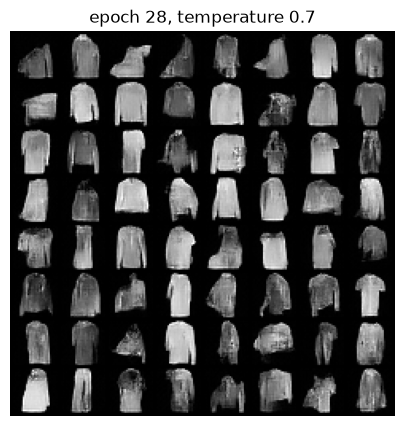

Epoch 28 summary:
   Train loss: -2247.98
   Val loss:   -2299.51
   Saved best model

Epoch 29/30
------------------------------
epoch 29 [0/215] loss -2307.53
epoch 29 [50/215] loss -2207.62
epoch 29 [100/215] loss -2233.84
epoch 29 [150/215] loss -2301.83
epoch 29 [200/215] loss -2255.41


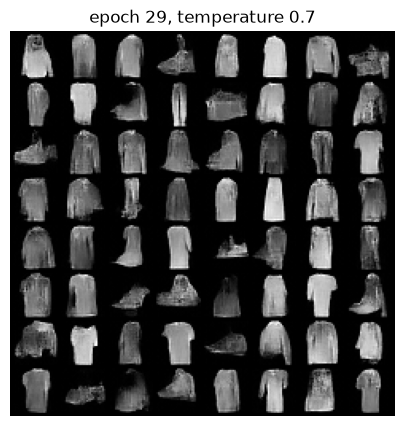

Epoch 29 summary:
   Train loss: -2280.45
   Val loss:   -2261.26

Epoch 30/30
------------------------------
epoch 30 [0/215] loss -2256.65
epoch 30 [50/215] loss -2300.61
epoch 30 [100/215] loss -2328.54
epoch 30 [150/215] loss -2318.04
epoch 30 [200/215] loss -2271.97


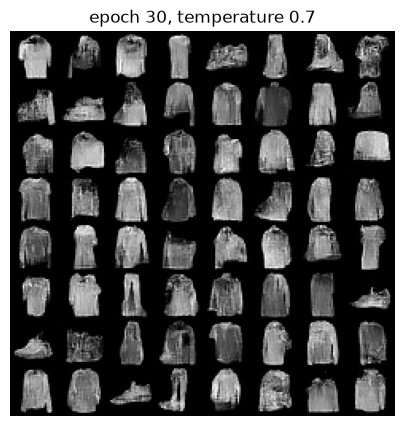

Epoch 30 summary:
   Train loss: -2267.06
   Val loss:   -2115.50

Training completed!
Test loss (best model): -2296.62


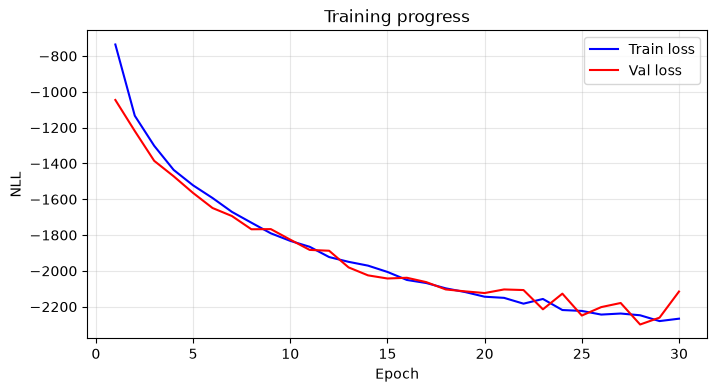

In [15]:
print('Starting training...')
print('=' * 50)
train_losses = []
val_losses = []
best_val = float('inf')
for epoch in range(1, EPOCHS + 1):
    print(f'\nEpoch {epoch}/{EPOCHS}')
    print('-' * 30)
    train_loss = train(epoch)
    val_loss = evaluate(val_loader)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    sample(epoch)
    print(f'Epoch {epoch} summary:')
    print(f'   Train loss: {train_loss:.2f}')
    print(f'   Val loss:   {val_loss:.2f}')
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), 'best_fashion.pth')
        print('   Saved best model')
print('\nTraining completed!')
print('=' * 50)
model.load_state_dict(torch.load('best_fashion.pth'))
test_loss = evaluate(test_loader)
print(f'Test loss (best model): {test_loss:.2f}')
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), train_losses, 'b-', label='Train loss')
plt.plot(range(1, EPOCHS + 1), val_losses, 'r-', label='Val loss')
plt.xlabel('Epoch')
plt.ylabel('NLL')
plt.title('Training progress')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

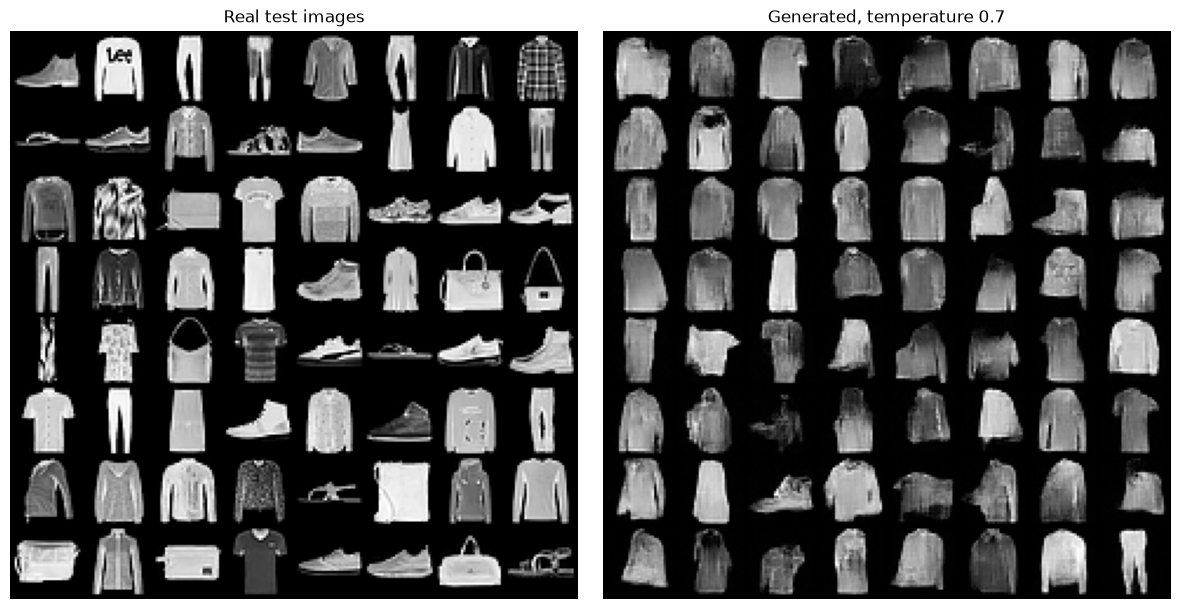

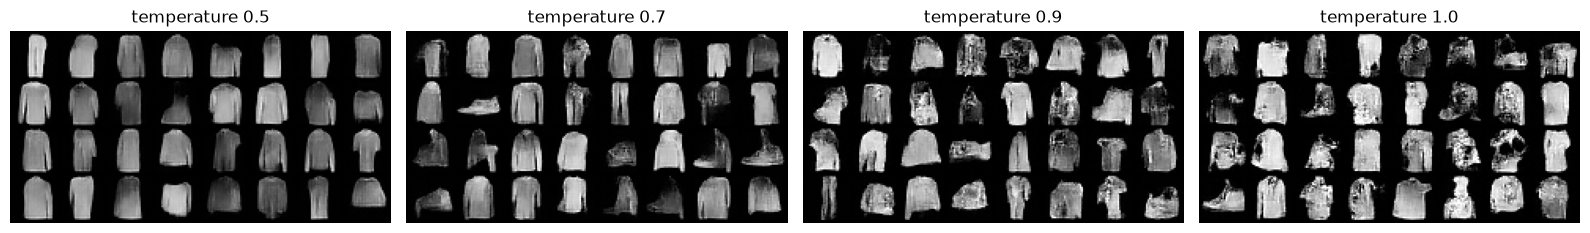

In [16]:
model.eval()
real, _ = next(iter(test_loader))
real = real[:64]
with torch.no_grad():
    generated = postprocess(model.sample(64, TEMPERATURE)).cpu()
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(vutils.make_grid(real, nrow=8).permute(1, 2, 0))
plt.title('Real test images')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(vutils.make_grid(generated, nrow=8).permute(1, 2, 0))
plt.title(f'Generated, temperature {TEMPERATURE}')
plt.axis('off')
plt.tight_layout()
plt.show()

temps = [0.5, 0.7, 0.9, 1.0]
plt.figure(figsize=(16, 4))
for i, t in enumerate(temps):
    with torch.no_grad():
        imgs = postprocess(model.sample(32, t)).cpu()
    plt.subplot(1, len(temps), i + 1)
    plt.imshow(vutils.make_grid(imgs, nrow=8).permute(1, 2, 0))
    plt.title(f'temperature {t}')
    plt.axis('off')
plt.tight_layout()
plt.show()

torch.Size([1000, 784]) 0.0019398406147956848


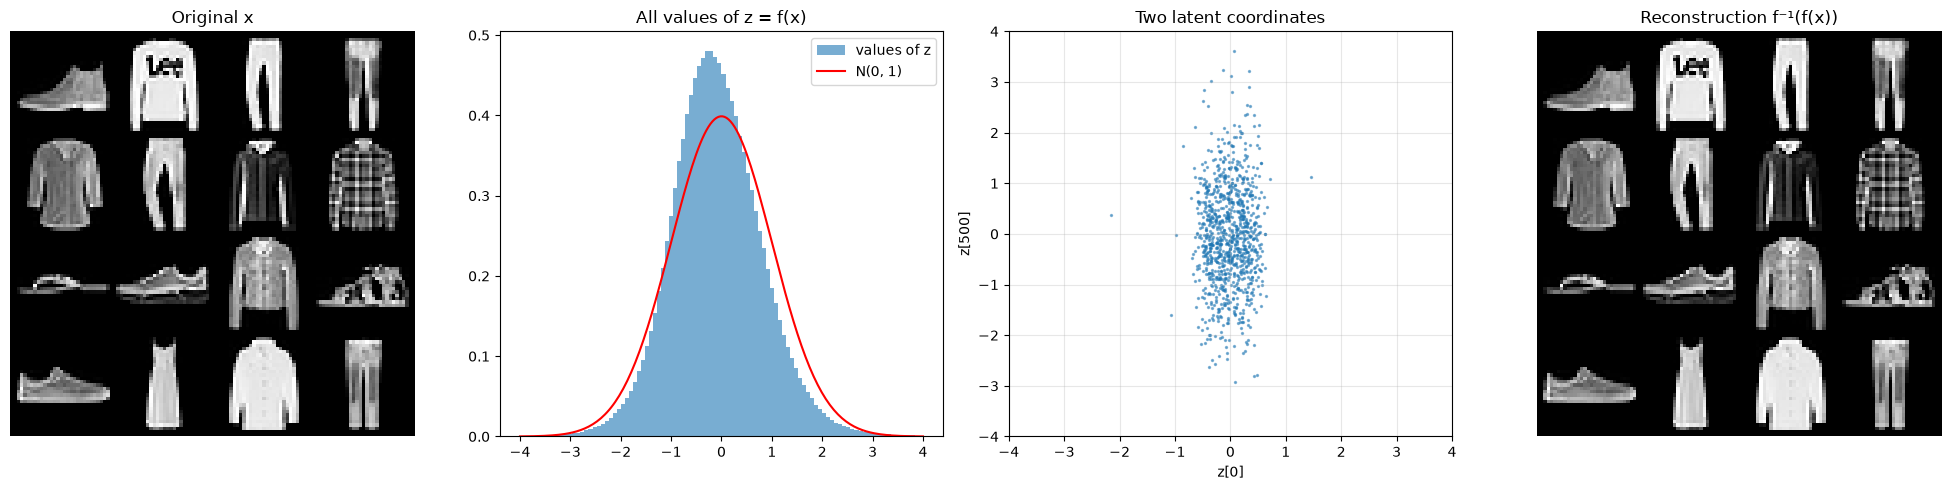

In [17]:
model.eval()
x = torch.stack([test_set[i][0] for i in range(1000)]).to(device)
x = preprocess(x)
with torch.no_grad():
    zs, _ = model(x)
    x_rec = model.inverse(zs)
z = torch.cat([zi.flatten(1) for zi in zs], dim=1).cpu()
print(z.shape, (x_rec - x).abs().max().item())
plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1)
plt.imshow(vutils.make_grid(postprocess(x[:16]).cpu(), nrow=4).permute(1, 2, 0))
plt.title('Original x')
plt.axis('off')
plt.subplot(1, 4, 2)
t = torch.linspace(-4, 4, 200)
plt.hist(z.flatten().numpy(), bins=100, range=(-4, 4), density=True, alpha=0.6, label='values of z')
plt.plot(t, torch.exp(-t ** 2 / 2) / math.sqrt(2 * math.pi), 'r', label='N(0, 1)')
plt.title('All values of z = f(x)')
plt.legend()
plt.subplot(1, 4, 3)
plt.scatter(z[:, 0], z[:, 500], s=2, alpha=0.5)
plt.xlim(-4, 4)
plt.ylim(-4, 4)
plt.xlabel('z[0]')
plt.ylabel('z[500]')
plt.title('Two latent coordinates')
plt.grid(True, alpha=0.3)
plt.subplot(1, 4, 4)
plt.imshow(vutils.make_grid(postprocess(x_rec[:16]).cpu(), nrow=4).permute(1, 2, 0))
plt.title('Reconstruction f⁻¹(f(x))')
plt.axis('off')
plt.tight_layout()
plt.show()